<a href="https://colab.research.google.com/github/tamarajovicic1/Data-Science-Masters/blob/main/titanic-survival-analysis/titanic_survival_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Ideja projekta:**

***Tema:*** Predviđanje preživljavanja na Titaniku po polu pomoću veštačke inteligencije

***Cilj:***

1. Analiza uticaja pola na šanse za preživljavanje:
Istražiti kako pol utiče na šanse za preživljavanje na Titaniku primenom različitih modela mašinskog učenja. Rezultate modela evaluirati pomoću metrika performansi i uporediti efikasnost svakog pristupa.
2. Ispitivanje uticaja porodice i partnera na preživljavanje:
Analizirati kako prisustvo članova porodice ili partnera utiče na verovatnoću preživljavanja pojedinca. Vizualizovati nalaze i kvantifikovati uticaj veličine porodice na šanse za preživljavanje.

**1. Čitanje i prikaz datasetova:**


In [1]:
import pandas as pd
train_data=pd.read_csv('train.csv')
test_data=pd.read_csv('test.csv')
gender_submission=pd.read_csv('gender_submission.csv')

**2. Prikaz dataseta Train i njegovih kolona i redova:**

In [2]:
train_data.info()
train_data.describe()
train_data.describe(include=['object'])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


**3. Grupisanje podataka za lakše manipulisanje podacima:**

In [3]:
#Grupisanje podataka u train_data po koloni za pol.
sex_survival = train_data.groupby('Sex')['Survived'].mean().reset_index()

In [4]:
#Grupisanje podataka u train_data po koloni SibSp(braća, sestre, partneri koji su na brodu zajedno), a zatim izračunava prosečnu vrednost kolone Survived za svaku grupu.
train_data.groupby(['SibSp'], as_index=False)['Survived'].mean()

,SibSp,Survived
0,0,0.345395
1,1,0.535885
2,2,0.464286
3,3,0.250000
4,4,0.166667
5,5,0.000000
6,8,0.000000


In [5]:
#Ova linija koda prikazuje spajanje kolona SibSp i Parch u jednu kolonu Family.
#Family predstavlja ukupan broj članova porodice koji putuju zajedno, uključujući i samu osobu(+1).
train_data['Family'] = train_data['SibSp'] + train_data['Parch'] + 1
test_data['Family'] = test_data['SibSp'] + test_data['Parch'] + 1

In [6]:
#Grupisanje podataka u train_data po napravljenoj koloni Family i analiza preživljavanja po veličini porodice.
family_survival = train_data.groupby('Family')['Survived'].mean().reset_index()

**4. Manipulacija i vizualizacija podacima**

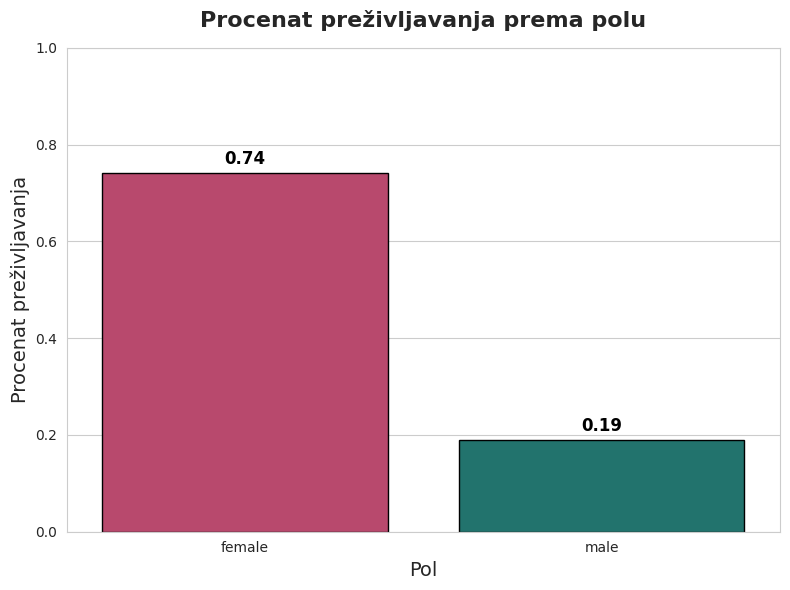

In [7]:
#Vizualizacija preživljavanja po polu koristeći Crayola boje
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.figure(figsize=(8, 6))
crayon_colors = sns.crayon_palette(['Jazzberry Jam', 'Pine Green'])
ax = sns.barplot(data=sex_survival, x='Sex', y='Survived', hue='Sex', palette=crayon_colors, edgecolor='black', legend=False)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 10), textcoords='offset points', fontsize=12, color='black', fontweight='bold')
plt.title('Procenat preživljavanja prema polu', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Pol', fontsize=14)
plt.ylabel('Procenat preživljavanja', fontsize=14)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


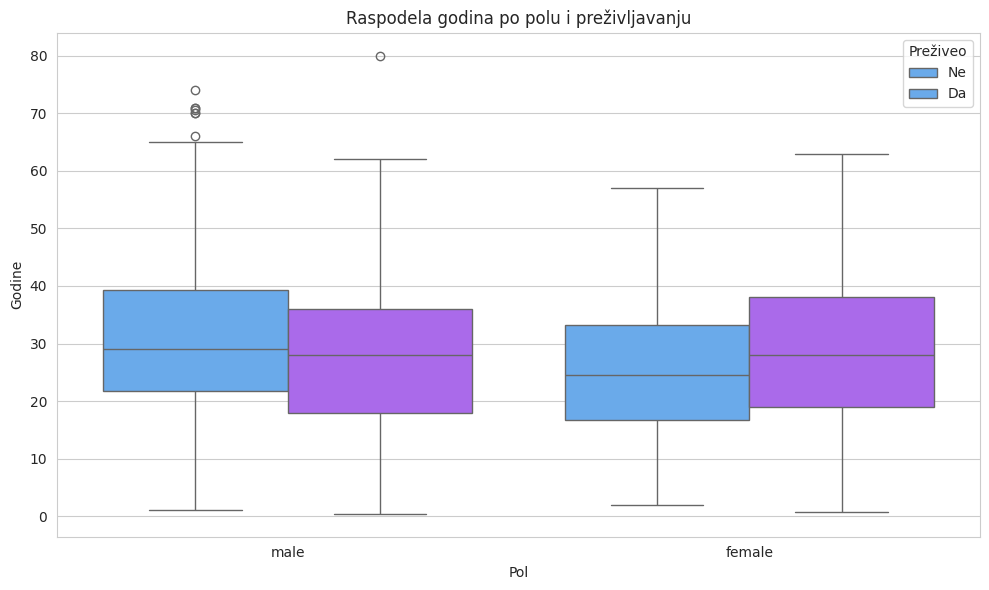

In [8]:
#Boxplot: Godine po polu i preživljavanju
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_data, x='Sex', y='Age', hue='Survived', palette='cool')
plt.title('Raspodela godina po polu i preživljavanju')
plt.xlabel('Pol')
plt.ylabel('Godine')
plt.legend(title='Preživeo', labels=['Ne', 'Da'])
plt.tight_layout()
plt.show()

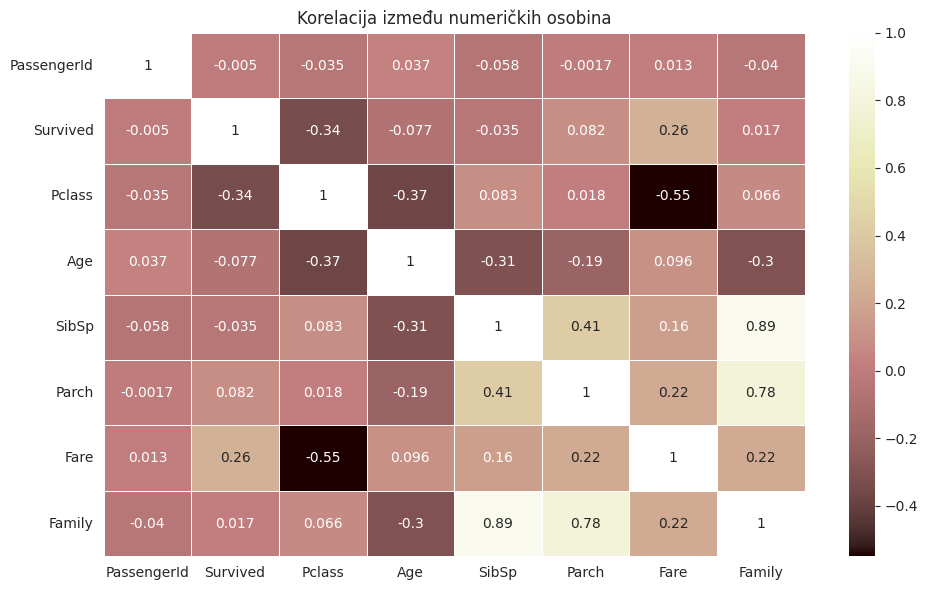

In [9]:
#Heatmap korelacije između numeričkih kolona
plt.figure(figsize=(10, 6))
corr_matrix = train_data.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap='pink', linewidths=0.5)
plt.title('Korelacija između numeričkih osobina')
plt.tight_layout()
plt.show()

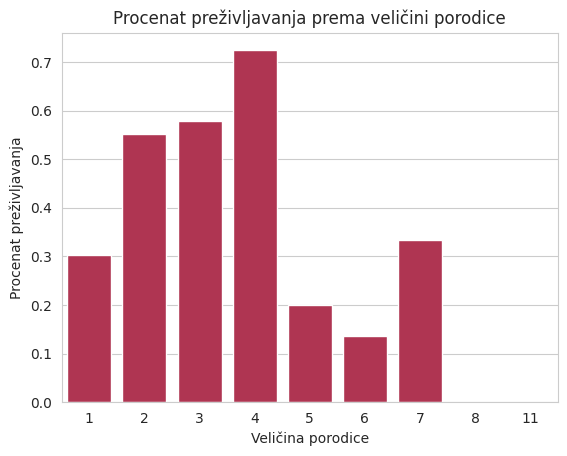

In [10]:
#Vizualizacija po veličini porodice
sns.barplot(data=family_survival, x='Family', y='Survived', color='#C32148')
plt.title('Procenat preživljavanja prema veličini porodice')
plt.xlabel('Veličina porodice')
plt.ylabel('Procenat preživljavanja')
plt.show()

**5. Inžinjering podataka**

In [11]:
#Spajanje test podataka sa predikcijama
test_data = test_data.merge(gender_submission, on='PassengerId')

In [12]:
#Rešavanje nedostajućih vrednosti
train_data['Age'] = train_data['Age'].fillna(train_data['Age'].median())
test_data['Age'] = test_data['Age'].fillna(test_data['Age'].median())
train_data['Embarked'] = train_data['Embarked'].fillna(train_data['Embarked'].mode()[0])
test_data['Fare'] = test_data['Fare'].fillna(test_data['Fare'].median())

In [13]:
train_data['Sex'] = train_data['Sex'].map({'male': 0, 'female': 1})
test_data['Sex'] = test_data['Sex'].map({'male': 0, 'female': 1})
train_data = pd.get_dummies(train_data, columns=['Embarked'], drop_first=True)
test_data = pd.get_dummies(test_data, columns=['Embarked'], drop_first=True)

In [14]:
#Inženjering titula iz imena
train_data['Title'] = train_data['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
test_data['Title'] = test_data['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
title_map = {
    "Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master"
}
train_data['Title'] = train_data['Title'].map(title_map)
test_data['Title'] = test_data['Title'].map(title_map)
train_data = pd.get_dummies(train_data, columns=['Title'], drop_first=True)
test_data = pd.get_dummies(test_data, columns=['Title'], drop_first=True)

<>:2: SyntaxWarning: invalid escape sequence '\.'
<>:3: SyntaxWarning: invalid escape sequence '\.'
<>:2: SyntaxWarning: invalid escape sequence '\.'
<>:3: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_2275/1062187597.py:2: SyntaxWarning: invalid escape sequence '\.'
  train_data['Title'] = train_data['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
/tmp/ipykernel_2275/1062187597.py:3: SyntaxWarning: invalid escape sequence '\.'
  test_data['Title'] = test_data['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [15]:
#Uklanjanje kolona koje ne koriste modelu
cols_to_drop = ['PassengerId', 'Name', 'Ticket', 'Cabin']
train_data.drop(columns=cols_to_drop, inplace=True)
test_data.drop(columns=cols_to_drop, inplace=True)

In [16]:
#Usklađivanje kolona
for col in set(train_data.columns) - set(test_data.columns) - {'Survived'}:
    test_data[col] = 0
test_data = test_data[train_data.drop('Survived', axis=1).columns]

In [17]:
#Skaliranje
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
train_data[['Age', 'Fare', 'Family']] = scaler.fit_transform(train_data[['Age', 'Fare', 'Family']])
test_data[['Age', 'Fare', 'Family']] = scaler.transform(test_data[['Age', 'Fare', 'Family']])

**6. Treniranje modela**

In [18]:
#Treniranje modela
from sklearn.model_selection import train_test_split
X = train_data.drop('Survived', axis=1)
y = train_data['Survived']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_val)

In [20]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_val)

**7. Rezultati predikcija**

In [21]:
#Rezultati+
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_val, y_pred_logreg))
print("Precision:", precision_score(y_val, y_pred_logreg))
print("F1 Score:", f1_score(y_val, y_pred_logreg))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_logreg))

print("\n=== Random Forest ===")
print("Accuracy:", accuracy_score(y_val, y_pred_rf))
print("Precision:", precision_score(y_val, y_pred_rf))
print("F1 Score:", f1_score(y_val, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred_rf))

=== Logistic Regression ===
Accuracy: 0.7877094972067039
Precision: 0.7432432432432432
F1 Score: 0.7432432432432432
Confusion Matrix:
 [[86 19]
 [19 55]]

=== Random Forest ===
Accuracy: 0.8268156424581006
Precision: 0.7945205479452054
F1 Score: 0.7891156462585034
Confusion Matrix:
 [[90 15]
 [16 58]]


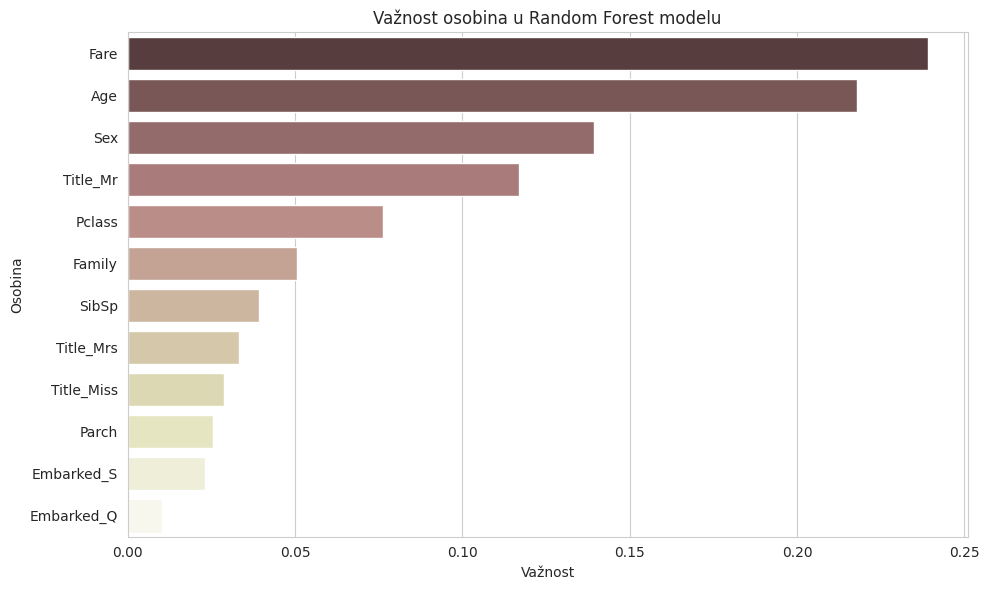

In [22]:
#Vizualizacija važnosti osobina
import numpy as np
importances = rf.feature_importances_
features = X.columns
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=features[indices], hue=features[indices], palette="pink", legend=False)
plt.title('Važnost osobina u Random Forest modelu')
plt.xlabel('Važnost')
plt.ylabel('Osobina')
plt.tight_layout()
plt.show()

## **8. Zaključak**
1. Pol ima značajan uticaj na preživljavanje: žene su imale znatno veći procenat preživljavanja u odnosu na muškarce. Vizuelizacija je potvrdila da je procenat preživelih žena bio više nego duplo veći.

2. Veličina porodice takođe igra ulogu: putnici koji su putovali sami imali su niže šanse za preživljavanje u poređenju sa onima koji su imali 2–4 člana porodice. Porodice sa više od 5 članova su takođe imali smanjene šanse za preživljavanje cele porodice.

3. Titule (npr. Mr, Miss) su bile korisne kao dodatne osobine pri treniranju modela. Korišćene su da bi se uvidelo koje titule imaju veće šanse za preživljavanje. Neke titule koje su ukazivale na mlađe putnike su pokazale manju šansu za preživljavanje a takodje i veću šansu za preživljavanje za starije putnike.

4. Random Forest model pokazao se boljim u predikciji u odnosu na Logistic Regression, prema većini evaluacionih osobina.